# Centered partition process informed by a network

Número de particiones: 203


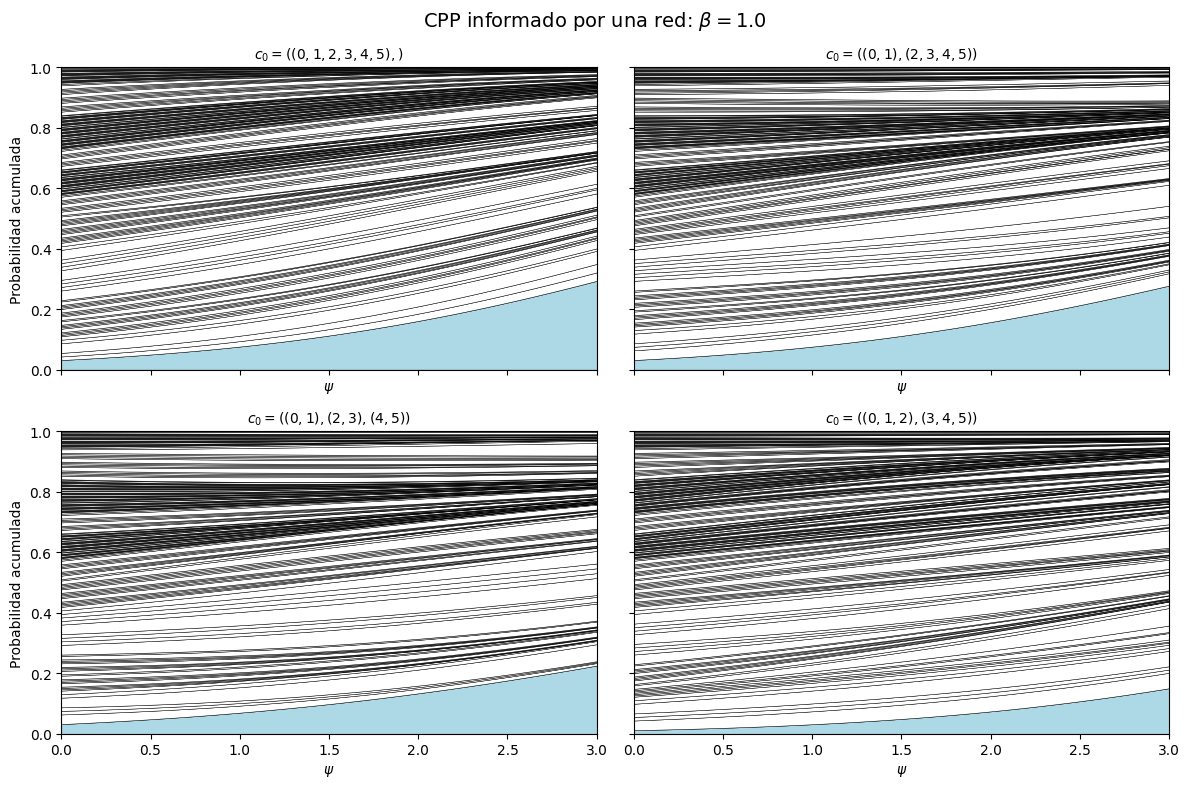

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from math import log

# ============================================================
# 1. Red binaria, simétrica y no dirigida
# ============================================================

n = 6

A = np.array([
    [0, 1, 0, 0, 0, 0],
    [1, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0, 0],
    [0, 0, 0, 0, 0, 1],
    [0, 0, 0, 0, 1, 0]
], dtype=int)

assert np.all(A == A.T)
assert np.all(np.diag(A) == 0)

# ============================================================
# 2. Enumerar todas las particiones de {0, ..., n-1}
#    mediante cadenas de crecimiento restringido
# ============================================================

def enumerate_partitions(n):
    partitions = []

    def backtrack(labels, max_label):
        if len(labels) == n:
            partitions.append(tuple(labels))
            return

        for k in range(max_label + 2):
            backtrack(labels + [k], max(max_label, k))

    backtrack([0], 0)
    return partitions


def blocks(c):
    """Representación de una partición como bloques."""
    return tuple(
        tuple(i for i, label in enumerate(c) if label == k)
        for k in sorted(set(c))
    )


partitions = enumerate_partitions(n)

print("Número de particiones:", len(partitions))
# Para n=5 debe ser 52.


# ============================================================
# 3. Distancia de información variacional (VI)
# ============================================================

def entropy(labels):
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / len(labels)
    return -sum(p * np.log(p) for p in probabilities)


def variation_of_information(c, c0):
    """
    VI(c, c0) = H(c) + H(c0) - 2 I(c, c0).
    Se usa logaritmo natural.
    """
    n = len(c)

    _, c_labels = np.unique(c, return_inverse=True)
    _, c0_labels = np.unique(c0, return_inverse=True)

    H_c = entropy(c_labels)
    H_c0 = entropy(c0_labels)

    mutual_information = 0.0

    for k in np.unique(c_labels):
        for l in np.unique(c0_labels):
            nij = np.sum(
                (c_labels == k) & (c0_labels == l)
            )

            if nij == 0:
                continue

            ni = np.sum(c_labels == k)
            nj = np.sum(c0_labels == l)

            mutual_information += (
                nij / n
                * np.log((nij * n) / (ni * nj))
            )

    return H_c + H_c0 - 2 * mutual_information


# ============================================================
# 4. Estadístico de red T(A, c)
# ============================================================

def network_statistic(A, c):
    """
    Número de aristas cuyos extremos están en el mismo bloque.
    """
    T = 0.0

    for i in range(len(c)):
        for j in range(i + 1, len(c)):
            if c[i] == c[j]:
                T += A[i, j]

    return T


# ============================================================
# 5. CPP informado por la red
# ============================================================

def partition_probabilities(partitions, c0, A, psi, beta):
    """
    p(c | c0, A, psi, beta)
      proporcional a p0(c) exp[-psi VI(c,c0) + beta T(A,c)].

    La distribución base es uniforme sobre las particiones.
    """
    log_weights = np.array([
        -psi * variation_of_information(c, c0)
        + beta * network_statistic(A, c)
        for c in partitions
    ])

    # Softmax estable numéricamente
    log_weights -= np.max(log_weights)
    weights = np.exp(log_weights)

    return weights / weights.sum()


# ============================================================
# 6. Particiones centrales para los cuatro paneles
# ============================================================

centers = [
    (0, 0, 0, 0, 0, 0),  # Un bloque
    (0, 0, 1, 1, 1, 1),  # Dos bloques
    (0, 0, 1, 1, 2, 2),  # Tres bloques
    (0, 0, 0, 1, 1, 1)   # Cuatro bloques
]

psi_values = np.linspace(0, 3, 151)

# beta > 0 favorece agrupar nodos conectados.
# beta = 0 recupera el CPP original.
beta = 1.0


# ============================================================
# 7. Figura de bandas acumuladas
# ============================================================

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8), sharex=True, sharey=True
)

for ax, c0 in zip(axes.flat, centers):

    # Probabilidad de cada partición para cada valor de psi
    P = np.array([
        partition_probabilities(
            partitions, c0, A, psi, beta
        )
        for psi in psi_values
    ]).T

    # Ordenar para que la partición central sea visible
    center_idx = partitions.index(c0)

    # Orden fijo: partición central primero
    order = [center_idx] + [
        i for i in range(len(partitions))
        if i != center_idx
    ]

    P = P[order]
    ordered_partitions = [partitions[i] for i in order]

    # Sumas acumuladas: cada banda representa una partición
    cumulative = np.vstack([
        np.zeros(len(psi_values)),
        np.cumsum(P, axis=0)
    ])

    for i in range(len(ordered_partitions)):
        color = "lightblue" if i == 0 else "white"

        ax.fill_between(
            psi_values,
            cumulative[i],
            cumulative[i + 1],
            color=color,
            edgecolor="black",
            linewidth=0.35
        )

    ax.set_title(
        rf"$c_0 = {blocks(c0)}$",
        fontsize=10
    )
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 1)
    ax.set_xlabel(r"$\psi$")
    ax.grid(False)

axes[0, 0].set_ylabel("Probabilidad acumulada")
axes[1, 0].set_ylabel("Probabilidad acumulada")

fig.suptitle(rf"CPP informado por una red: $\beta={beta}$", fontsize=14)

plt.tight_layout()
plt.show()


Número de particiones: 203
Número de aristas m: 5
Máximo observado de VI/log(n): 1.0000
Mínimo y máximo de T*: 0.0000, 1.0000
Mínimo y máximo de 1-T*: 0.0000, 1.0000


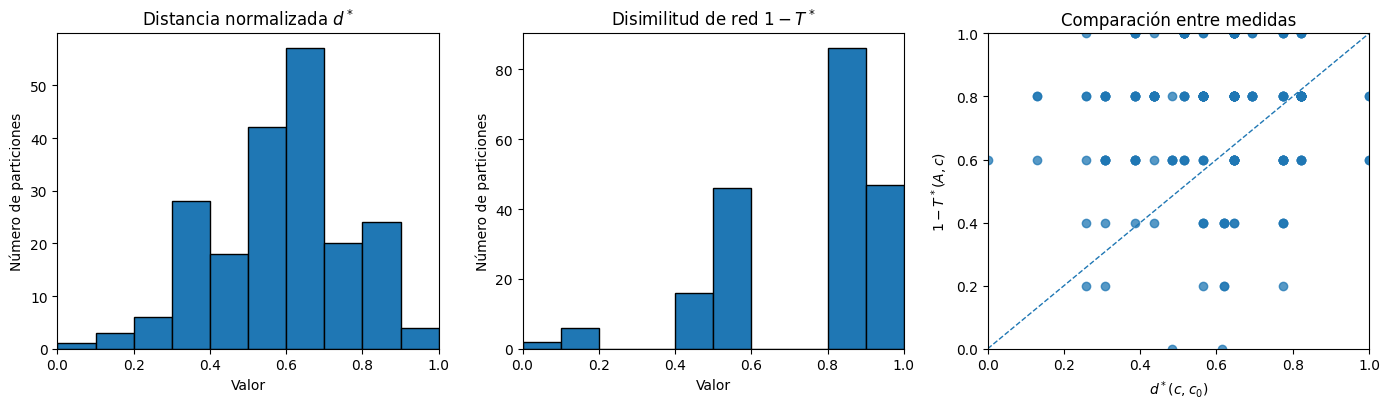

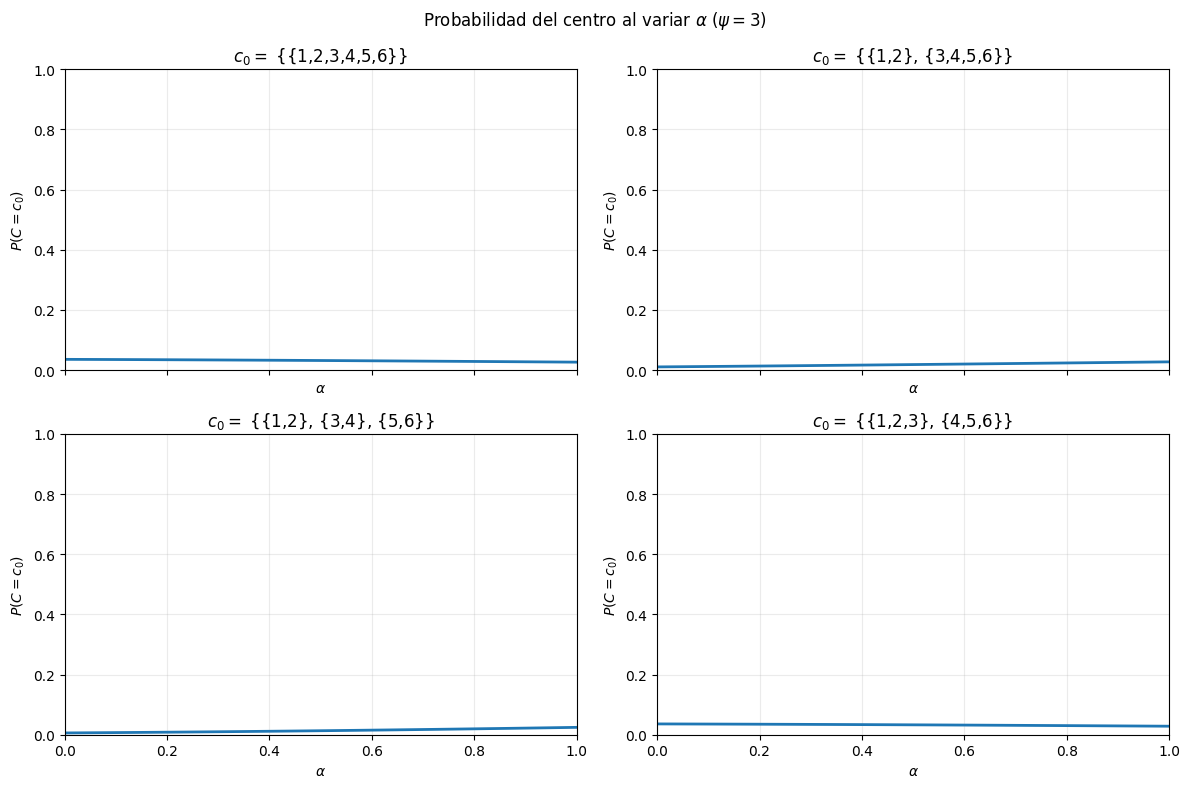

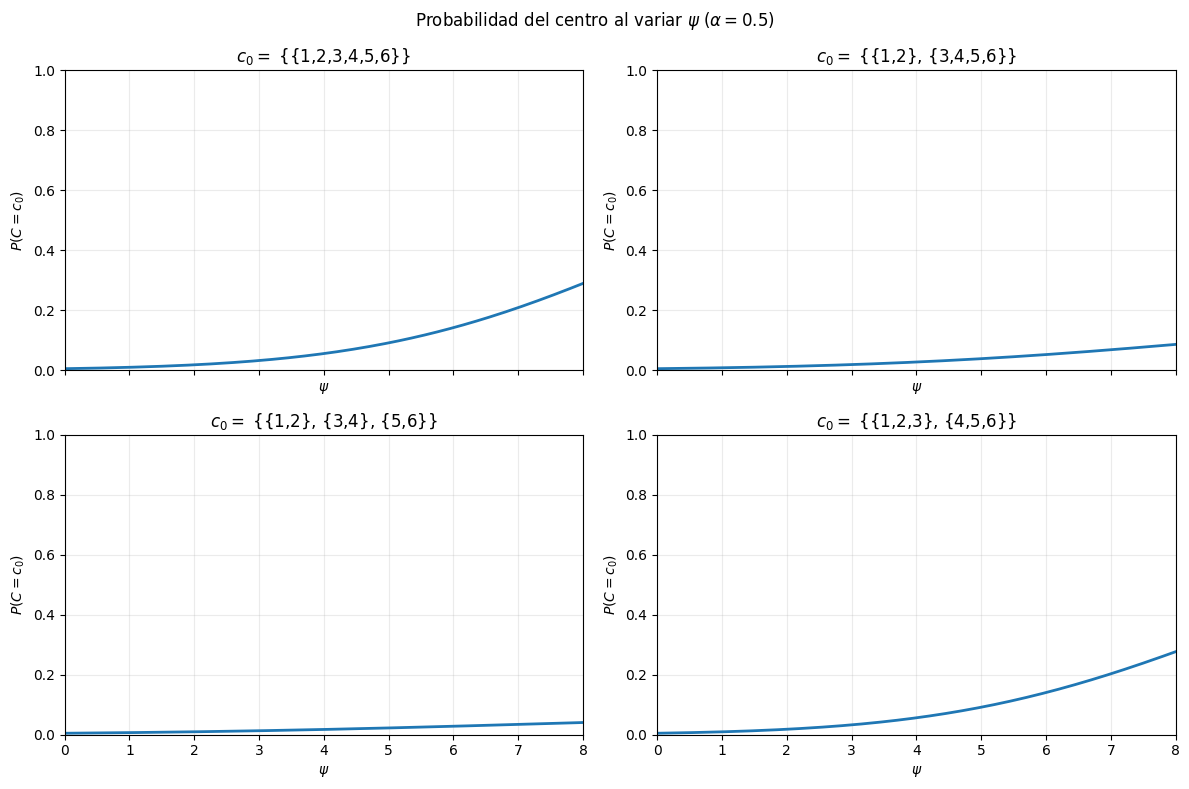

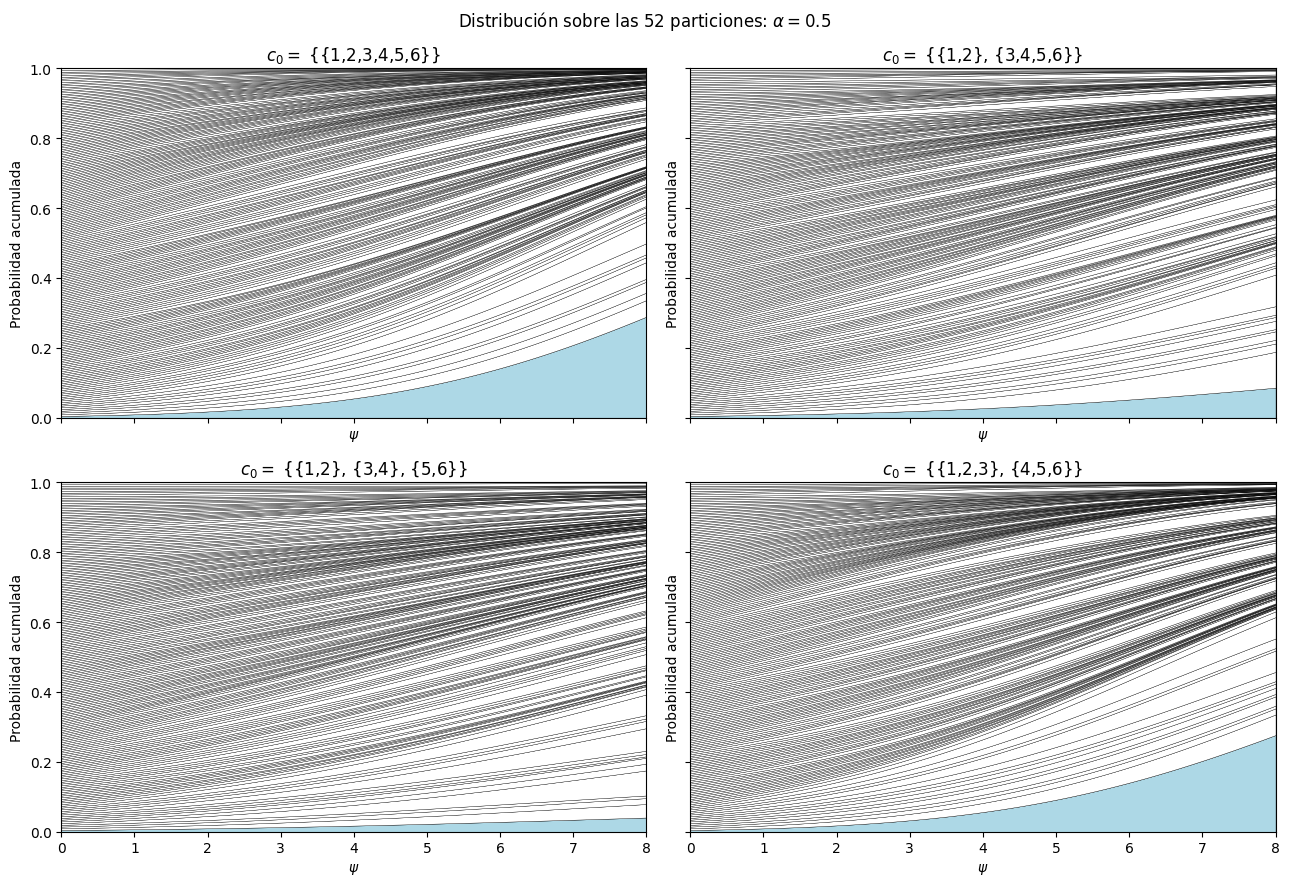

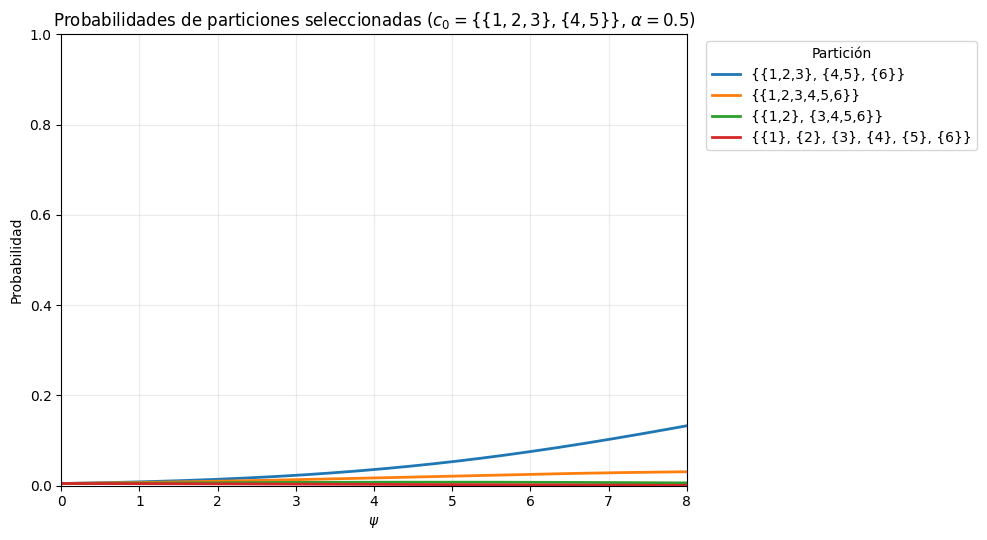

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from itertools import product

# ============================================================
# 1. Red binaria, simétrica y no dirigida
# ============================================================
n = 6

A = np.array([
    [0, 1, 1, 0, 0, 0],
    [1, 0, 1, 0, 0, 0],
    [1, 1, 0, 0, 0, 0],
    [0, 0, 0, 0, 1, 0],
    [0, 0, 0, 1, 0, 1],
    [0, 0, 0, 0, 1, 0]
], dtype=int)

assert np.all(A == A.T), "A debe ser simétrica."
assert np.all(np.diag(A) == 0), "La diagonal debe ser cero."
assert np.all(np.isin(A, [0, 1])), "La red debe ser binaria."

m = int(np.triu(A, k=1).sum())
if m == 0:
    raise ValueError("La red debe tener al menos una arista.")

# ============================================================
# 2. Enumerar particiones con restricted growth strings
# ============================================================
def enumerate_partitions(n):
    partitions = []

    def backtrack(labels, max_label):
        if len(labels) == n:
            partitions.append(tuple(labels))
            return
        for k in range(max_label + 2):
            backtrack(labels + [k], max(max_label, k))

    backtrack([0], 0)
    return partitions

partitions = enumerate_partitions(n)
assert len(partitions) == 203

def blocks(c):
    return tuple(
        tuple(i + 1 for i, label in enumerate(c) if label == k)
        for k in sorted(set(c))
    )

def partition_label(c):
    return "{" + ", ".join(
        "{" + ",".join(map(str, b)) + "}" for b in blocks(c)
    ) + "}"

# ============================================================
# 3. VI y su normalización
# ============================================================
def entropy(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / len(labels)
    return -np.sum(p * np.log(p))

def variation_of_information(c, c0):
    c = np.asarray(c)
    c0 = np.asarray(c0)
    n_local = len(c)

    _, cl = np.unique(c, return_inverse=True)
    _, c0l = np.unique(c0, return_inverse=True)

    Hc = entropy(cl)
    Hc0 = entropy(c0l)
    mutual_information = 0.0

    for k in np.unique(cl):
        for ell in np.unique(c0l):
            nij = np.sum((cl == k) & (c0l == ell))
            if nij == 0:
                continue
            ni = np.sum(cl == k)
            nj = np.sum(c0l == ell)
            mutual_information += (nij / n_local) * np.log(
                (nij * n_local) / (ni * nj)
            )

    return max(0.0, Hc + Hc0 - 2 * mutual_information)

VI_MAX = np.log(n)

def normalized_vi(c, c0):
    return variation_of_information(c, c0) / VI_MAX

# ============================================================
# 4. Estadístico de red y normalización
# ============================================================
def network_statistic(A, c):
    return float(sum(
        A[i, j]
        for i in range(len(c))
        for j in range(i + 1, len(c))
        if c[i] == c[j]
    ))

def normalized_network_statistic(A, c):
    return network_statistic(A, c) / m

def combined_dissimilarity(c, c0, A, alpha):
    d = normalized_vi(c, c0)
    t = normalized_network_statistic(A, c)
    return alpha * d + (1 - alpha) * (1 - t)

# ============================================================
# 5. Probabilidades CPP con combinación convexa
# ============================================================
def partition_probabilities(partitions, c0, A, psi, alpha):
    D = np.array([
        combined_dissimilarity(c, c0, A, alpha)
        for c in partitions
    ])
    log_weights = -psi * D
    log_weights -= log_weights.max()  # estabilidad numérica
    weights = np.exp(log_weights)
    return weights / weights.sum()

# ============================================================
# 6. Centros ilustrativos
# ============================================================
centers = [
    (0, 0, 0, 0, 0, 0),  # un bloque
    (0, 0, 1, 1, 1, 1),  # dos bloques
    (0, 0, 1, 1, 2, 2),  # tres bloques
    (0, 0, 0, 1, 1, 1)   # dos bloques: {1,2,3} y {4,5,6}
]

# ============================================================
# 7. Comprobar y visualizar normalización de las medidas
# ============================================================
c0_norm = centers[2]
d_values = np.array([normalized_vi(c, c0_norm) for c in partitions])
t_values = np.array([normalized_network_statistic(A, c) for c in partitions])
network_dissimilarity = 1 - t_values

print(f"Número de particiones: {len(partitions)}")
print(f"Número de aristas m: {m}")
print(f"Máximo observado de VI/log(n): {d_values.max():.4f}")
print(f"Mínimo y máximo de T*: {t_values.min():.4f}, {t_values.max():.4f}")
print(f"Mínimo y máximo de 1-T*: {network_dissimilarity.min():.4f}, "
      f"{network_dissimilarity.max():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

axes[0].hist(d_values, bins=np.linspace(0, 1, 11), edgecolor="black")
axes[0].set_title(r"Distancia normalizada $d^*$")
axes[0].set_xlabel("Valor")
axes[0].set_ylabel("Número de particiones")
axes[0].set_xlim(0, 1)

axes[1].hist(network_dissimilarity, bins=np.linspace(0, 1, 11),
             edgecolor="black")
axes[1].set_title(r"Disimilitud de red $1-T^*$")
axes[1].set_xlabel("Valor")
axes[1].set_ylabel("Número de particiones")
axes[1].set_xlim(0, 1)

axes[2].scatter(d_values, network_dissimilarity, alpha=0.75)
axes[2].plot([0, 1], [0, 1], linestyle="--", linewidth=1)
axes[2].set_title("Comparación entre medidas")
axes[2].set_xlabel(r"$d^*(c,c_0)$")
axes[2].set_ylabel(r"$1-T^*(A,c)$")
axes[2].set_xlim(0, 1)
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

# ============================================================
# 8. Curvas de probabilidad del centro al variar alpha
# ============================================================
alpha_values = np.linspace(0, 1, 101)
psi_fixed = 3.0

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, c0 in zip(axes.flat, centers):
    idx = partitions.index(c0)
    p_center = [
        partition_probabilities(partitions, c0, A, psi_fixed, alpha)[idx]
        for alpha in alpha_values
    ]
    ax.plot(alpha_values, p_center, linewidth=2)
    ax.set_title(r"$c_0=$ " + partition_label(c0))
    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(r"$P(C=c_0)$")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)

fig.suptitle(r"Probabilidad del centro al variar $\alpha$ ($\psi=3$)")
plt.tight_layout()
plt.show()

# ============================================================
# 9. Curvas de probabilidad del centro al variar psi
# ============================================================
psi_values = np.linspace(0, 8, 161)
alpha_fixed = 0.5

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, c0 in zip(axes.flat, centers):
    idx = partitions.index(c0)
    p_center = [
        partition_probabilities(partitions, c0, A, psi, alpha_fixed)[idx]
        for psi in psi_values
    ]
    ax.plot(psi_values, p_center, linewidth=2)
    ax.set_title(r"$c_0=$ " + partition_label(c0))
    ax.set_xlabel(r"$\psi$")
    ax.set_ylabel(r"$P(C=c_0)$")
    ax.set_xlim(0, 8)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)

fig.suptitle(r"Probabilidad del centro al variar $\psi$ ($\alpha=0.5$)")
plt.tight_layout()
plt.show()

# ============================================================
# 10. Bandas acumuladas para varias particiones centrales
#     Cada banda representa una partición; azul = centro.
# ============================================================
psi_band = np.linspace(0, 8, 121)
alpha_band = 0.5

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)

for ax, c0 in zip(axes.flat, centers):
    P = np.array([
        partition_probabilities(partitions, c0, A, psi, alpha_band)
        for psi in psi_band
    ]).T

    center_idx = partitions.index(c0)
    order = [center_idx] + [i for i in range(len(partitions)) if i != center_idx]
    P = P[order]

    cumulative = np.vstack([
        np.zeros(len(psi_band)),
        np.cumsum(P, axis=0)
    ])

    for i in range(len(order)):
        ax.fill_between(
            psi_band, cumulative[i], cumulative[i + 1],
            color="lightblue" if i == 0 else "white",
            edgecolor="black", linewidth=0.25
        )

    ax.set_title(r"$c_0=$ " + partition_label(c0))
    ax.set_xlabel(r"$\psi$")
    ax.set_ylabel("Probabilidad acumulada")
    ax.set_xlim(psi_band.min(), psi_band.max())
    ax.set_ylim(0, 1)

fig.suptitle(r"Distribución sobre las 52 particiones: $\alpha=0.5$")
plt.tight_layout()
plt.show()

# ============================================================
# 11. Comparar probabilidades de varias particiones específicas
# ============================================================
selected_partitions = [
    (0, 0, 0, 1, 1, 2),  # {1,2,3}, {4,5}, {6}: componentes de la red
    (0, 0, 0, 0, 0, 0),  # un bloque
    (0, 0, 1, 1, 1, 1),  # dos bloques
    (0, 1, 2, 3, 4, 5)   # todos singleton
]

c0 = (0, 0, 0, 1, 1, 2)
alpha_compare = 0.5
psi_compare = np.linspace(0, 8, 161)

fig, ax = plt.subplots(figsize=(10, 5.5))
for c in selected_partitions:
    idx = partitions.index(c)
    probs = [
        partition_probabilities(partitions, c0, A, psi, alpha_compare)[idx]
        for psi in psi_compare
    ]
    ax.plot(psi_compare, probs, linewidth=2, label=partition_label(c))

ax.set_title(
    r"Probabilidades de particiones seleccionadas "
    r"($c_0=\{\{1,2,3\},\{4,5\}\}$, $\alpha=0.5$)"
)
ax.set_xlabel(r"$\psi$")
ax.set_ylabel("Probabilidad")
ax.set_xlim(0, 8)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend(title="Partición", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
